In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Due to a Jupyter bug, the %matplotlib inline "magic" command needs to be in 
# its own cell. See:
# https://github.com/jupyter/notebook/issues/3385

%matplotlib inline

In [3]:
import numpy as np

import matplotlib
import matplotlib.pyplot as plt

# Adjust default font size so that labels are readable in plots
font = {'size': 16}
matplotlib.rc('font', **font)
matplotlib.rcParams['savefig.dpi'] = 300
matplotlib.rcParams['figure.dpi'] = 200
matplotlib.rcParams['figure.figsize'] = [6,3]

# Choosing the _right_ model

Statistics like the KS-test (for univariate distributions) or $\chi^2$ (for regressions) tell us if a model is an acceptable fit or not.

But suppose that instead we want to compare two _different_ models, which may have different numbers of free parameters.

For example, suppose we compare a straight line to a quadratic fit. Now also suppose that, in reality, the data are generated from a straight line plus noise. Because of random fluctuations in the data set it will usually be true that sample has some curvature and will be better fit by a quadratic. This is called _overfitting_. 

In [4]:
def parab(x,a,b,c):
    y = a*x**2+b*x+c
    return y

def line(x,b,c):
    y = b*x+c
    return y

In [5]:
a = 0.5
b = 1.
c = 0.
scat = 1
xmin = 0.
xmax = 2.
nx = 11

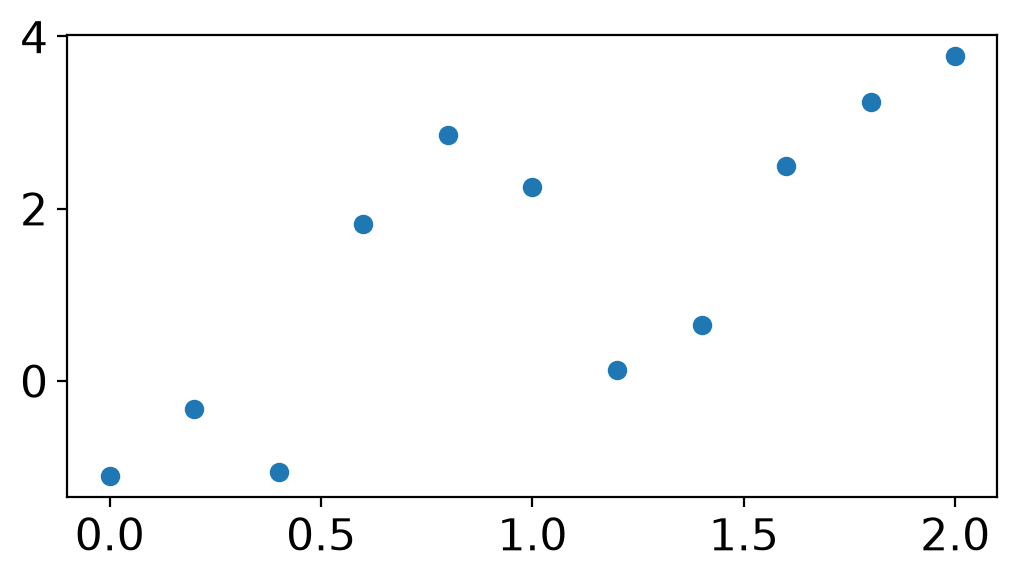

In [6]:
x = np.linspace(xmin,xmax,nx)
y = parab(x,a,b,c) + scat*np.random.randn(len(x))
plt.plot(x,y,'o');

In [7]:
def plot_and_fit(xmin=0., xmax=2., nx=11,  a=0., b=0., c=0., scat=1.):

    x = np.linspace(xmin,xmax,nx)
    y = parab(x,a,b,c) + scat*np.random.randn(len(x))
    plt.plot(x,y,'o')

    xplot = np.linspace(xmin,xmax,101)
    p, residuals, rank, singular_values, rcond = np.polyfit(x, y, deg=1, full=True)
    print("Line parameters", p, "sum of squares",residuals)
    plt.plot(xplot,line(xplot,*p))

    p, residuals, rank, singular_values, rcond = np.polyfit(x, y, deg=2, full=True)
    print("Parabola parameters", p, "sum of squares",residuals)
    plt.plot(xplot,parab(xplot,*p))

Line parameters [1.45583573 0.37298817] sum of squares [3.7081417]
Parabola parameters [ 0.78667201 -0.11750829  0.84499137] sum of squares [2.85858051]


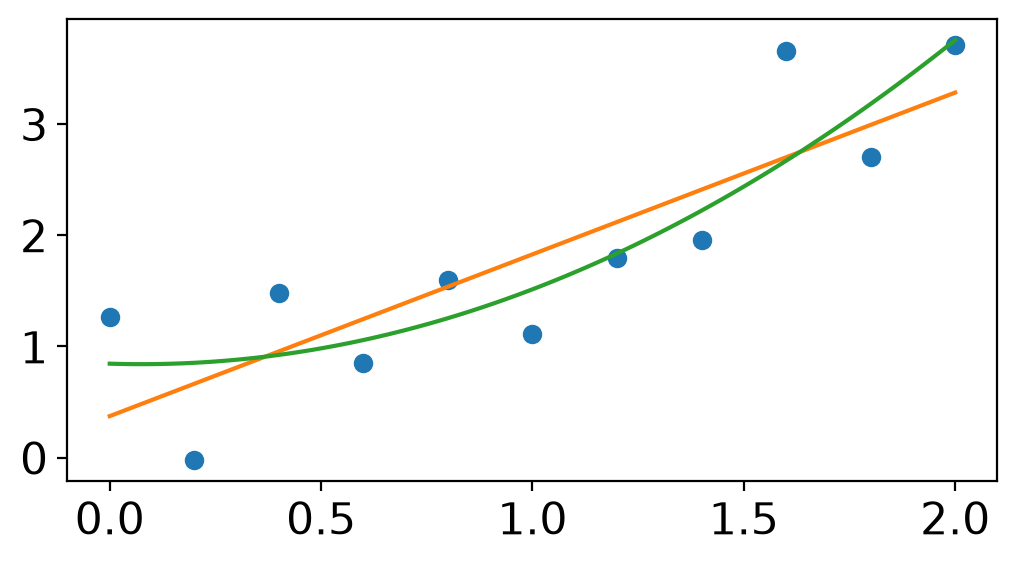

In [8]:
plot_and_fit(xmin, xmax, nx=11, a=a, b=b, c=c)

Line parameters [ 1.78779627 -0.11723551] sum of squares [103.40286449]
Parabola parameters [0.45842311 0.87095004 0.18532375] sum of squares [101.44052358]


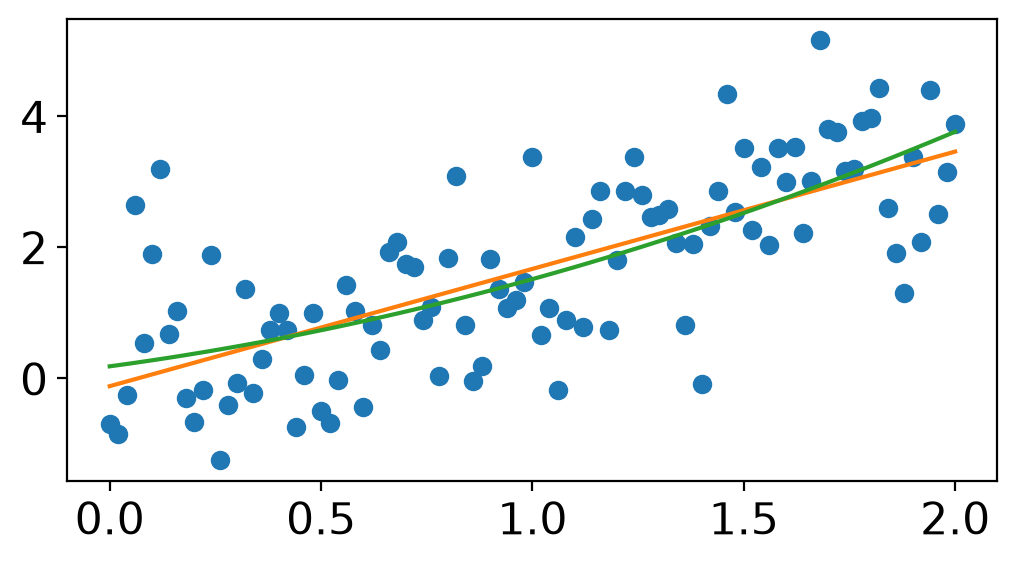

In [14]:
plot_and_fit(xmin, xmax, nx=101, a=a, b=b, c=c)

Line parameters [ 2.05356865 -0.39345277] sum of squares [1030.38457904]
Parabola parameters [ 0.4855882   1.08239225 -0.07005103] sum of squares [1009.32004086]


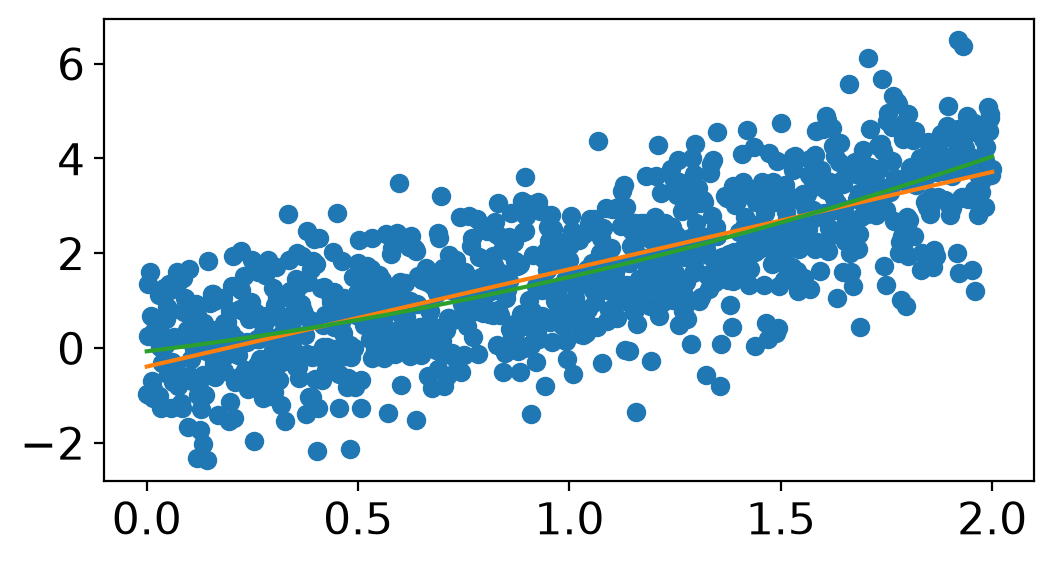

In [15]:
plot_and_fit(xmin, xmax, nx=1001, a=a, b=b, c=c)

So clearly $\chi^2$ will be lower for the model with extra terms.

We need a way to figure out whether the extra terms lead to a _large enough_ drop in $\chi^2$.

## Wilks test

Used for "nested" models, like the one above, where we compare two parameter sets where one (2) is a restricted version of the other (1). For exmaple, a straight line line (2) is a parabola (1) with $a = 0$. The likelihood of $L_1 > L_2$.

Compare the difference: $-2 \ln(L_2) - 2\ln(L_1)$. As $n \rightarrow \infty$, this difference should be distributed as $\chi^2$ with $k_1 - k_2$ dof. 

## Aikake Information Criterion

This is used to _compare_ models to each other, by comparing the difference in AIC. (The AIC by itself has no meaning).

Let $\hat L$ be the maximum value of the likelihood function for a model with $k$ parameters. Then the AIC value of the model is: 

$$
\mathrm{AIC} \, = \, 2k - 2\ln(\hat L)
$$

The model with the lower AIC is better. 

Note that if the residuals are Gaussian then $-2\ln(\hat L) = \chi^2 + \mathrm{const}$ 

For small $N$ data samples, a correction is applied

$$
\mathrm{AICc} \, = \, \mathrm{AIC} + \frac{2k^2 + 2k}{N - k - 1}
$$

## Bayesian Information Criterion

BIC is similar to AIC. If there are $N$ data: 

$\mathrm{BIC} = {\ln(N)k - 2\ln({\hat L})}$

However, if the difference in BIC between two models is not large, then the _significance_ of the claim that the model with the lower BIC is better, is low. The Jeffreys scale:

| $\Delta$BIC | Evidence against higher BIC |
| --- | --- |
| 0 to 2 | Not worth more than a bare mention |
| 2 to 6 | Positive |
| 6 to 10 | Strong |
| >10 | Very Strong |

## Which should I use?

My preference has always been Wilks test. 

The difference between the AIC and BIC is how much penalty is applied:

$2k$ (AIC) vs $\ln(N)k$ (BIC)

For large $N$, BIC will have a larger penalty than AIC for a model with more parameters.

If possible, do _all_.  If they disagree, then report all.

## Example: Gaussian Mixture Model

(See textbook section 4.4)



![Figure 4.2](http://www.astroml.org/_images/fig_GMM_1D_1.png)

Example of a one-dimensional Gaussian mixture model with three components. The left panel shows a histogram of the data, along with the best-fit model for a mixture with three components. The center panel shows the model selection criteria AIC and BIC  as a function of the number of components. Both are minimized for a three-component model. The right panel shows the probability that a given point is drawn from each class as a function of its position. For a given x value, the vertical extent of each region is proportional to that probability. Note that extreme values are most likely to belong to class 1.

## Cross-validation

The basic idea is to split the sample, and use part of of it to fit the model, and the remainder to assess goodness of fit.

There are many ways to do cross-validation in practice. 


### One cross-validation example

This idea works well if the data set is relatively large (e.g. training sets for neural nets).

Suppose you have $n$ data of the form $y = f(x)$ that you would like to fit with some models. For a concrete example, suppose the models are polynomials of degree $k$.

Split the $x, y$ data into three sets (randomly):

1. Training set (50-70%) of the data
2. Cross-validation set (half of the rest)
3. Test set (other half of the rest)

For the training set, for each model (e.g. polynomial of degree $k$), record the parameters of best fit and the rms of the residuals from the fit. The rms will of course decline with increasing $k$.

Now in the cross-validation set, compare the rms for each fit, as a function of $k$. Since the cross-validation set is independent of the training set, a model that overfits the training set will produce a larger rms in the cross-validation set. Use this to choose the best model.

Finally, having fixed the best model (e.g. the degree of the polynomial) and having fixed that model's parameters from the training set,  use the test set to evaluate the rms.